# Penguin Species Classification Using Multinomial Logistic Regression

## 1. Introduction

Machine learning is widely used to solve classification problems in different fields, including healthcare, finance, biology, and environmental research.

In this project, I will develop a **Multinomial Logistic Regression** model to classify penguins into three different species based on their physical measurements.

The project uses the Palmer Penguins dataset, which contains physical characteristics of penguins observed in the Palmer Archipelago, Antarctica.

## 2. Problem Statement

Identifying penguin species based on physical characteristics can be treated as a multiclass classification problem.

The objective of this project is to develop a machine learning model that predicts the species of a penguin using its physical measurements.

The model will classify penguins into three categories:
- Adelie
- Chinstrap
- Gentoo

## 3. Project Objectives

- Understand and explore the Palmer Penguins dataset.
- Perform data cleaning and preprocessing.
- Analyze relationships between physical measurements and penguin species.
- Implement Multinomial Logistic Regression.
- Evaluate model performance using appropriate classification metrics.
- Interpret the model's predictions and identify its limitations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
df = pd.read_csv('penguins.csv')
df.head(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## 4. Dataset Overview

**Target Variable:** `species`

The dataset contains information about three penguin species and their physical characteristics.

### Dataset Features

| Feature | Description |
|---|---|
| species | Penguin species (target variable) |
| bill_length_mm | Bill length in millimeters |
| bill_depth_mm | Bill depth in millimeters |
| flipper_length_mm | Flipper length in millimeters |
| body_mass_g | Body mass in grams |
| island | Island where the penguin was observed |
| sex | Penguin sex |
| year | Observation year |

For this project, four numerical physical measurements will be used as independent variables, while `species` will be used as the target variable.

## 5. Data Cleaning and Preprocessing

Before training the model, the dataset will be examined and prepared.

The following tasks will be performed:

- Inspect dataset structure and data types.
- Identify missing values and duplicate records.
- Handle missing values appropriately.
- Select relevant numerical features.


In [42]:
# Extract the only those columns/relevant features that we will use in this project
df = pd.DataFrame(df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'species']])
df.head(3)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species
0,39.1,18.7,181.0,3750.0,Adelie
1,39.5,17.4,186.0,3800.0,Adelie
2,40.3,18.0,195.0,3250.0,Adelie


In [43]:
# check number of columns and rows
df.shape

(344, 5)

In [44]:
# check dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bill_length_mm     342 non-null    float64
 1   bill_depth_mm      342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   species            344 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


In [45]:
# identify missing values
df.isnull().sum()

bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
species              0
dtype: int64

In [46]:
# Fill missing values with median of the columns
for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

In [47]:
# identify missing values again
df.isnull().sum()

bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
species              0
dtype: int64

In [48]:
# identify duplicate records
df.duplicated().sum()

np.int64(0)

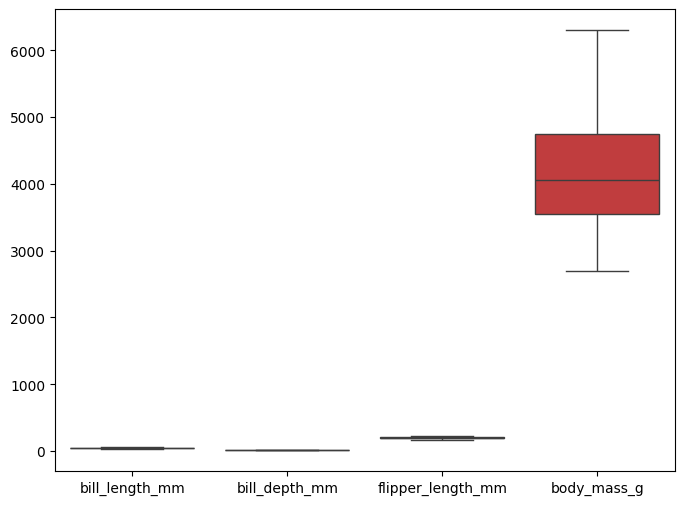

In [49]:
# check outlier
plt.figure(figsize=(8,6))
sns.boxplot(data=df)
plt.show()

## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis will be performed to understand the dataset and identify patterns in the physical measurements of different penguin species.

The analysis will include:

- Species distribution analysis.
- Descriptive statistics.
- Pair plots to examine relationships between features.

In [50]:
# descriptive statistics
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,344.000000,344.000000,344.000000,344.000000
mean,43.925000,17.152035,200.892442,4200.872093
std,5.443792,1.969060,14.023826,799.696532
min,32.100000,13.100000,172.000000,2700.000000
25%,39.275000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


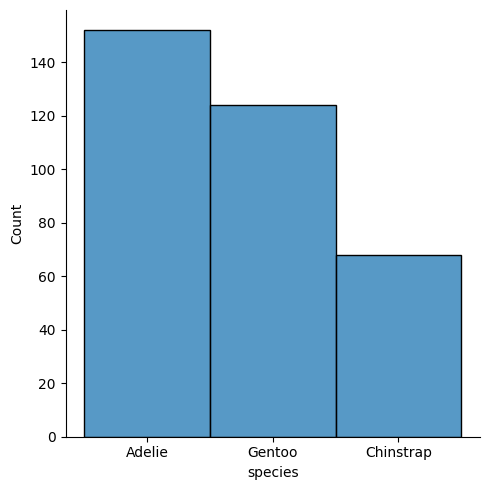

In [51]:
# species distribution
sns.displot(df['species'])
plt.show()

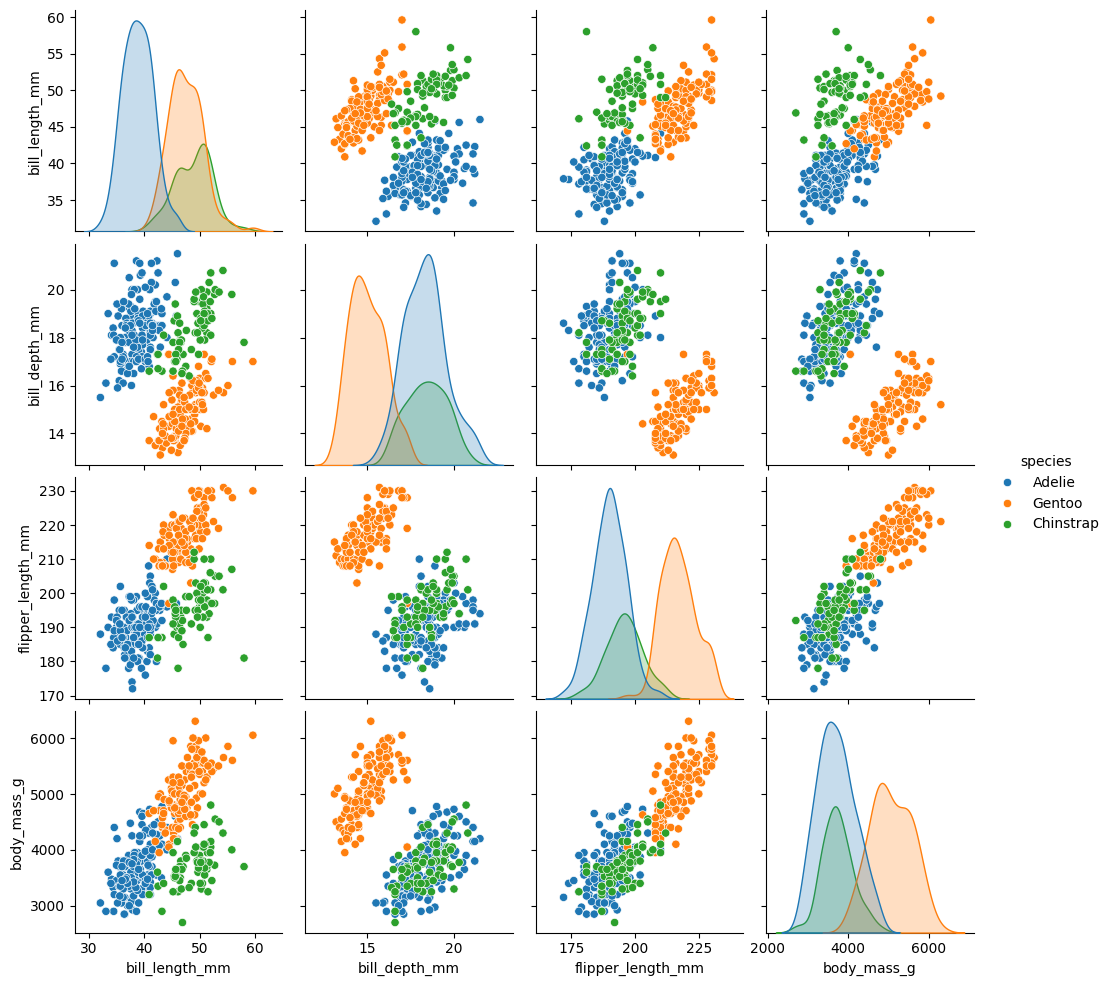

In [52]:
sns.pairplot(data=df,hue='species')
plt.show()

In [56]:
# Create input and output variables
x = df.iloc[:, :-1]
y = df['species']

#### Feature Scaling

In [57]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(x)
X = pd.DataFrame(sc.transform(x), columns=x.columns)

## 7. Model Development: Multinomial Logistic Regression

Multinomial Logistic Regression is a supervised machine learning algorithm used for classification problems involving more than two classes.

Unlike binary logistic regression, which predicts between two categories, multinomial logistic regression can classify observations into multiple categories.

In this project, the algorithm will predict one of three penguin species based on their physical measurements.

### Model Training

The model will be trained using the selected numerical features and corresponding species labels.

### Model Prediction

After training, the model will predict the species of penguins in the test dataset.

In [60]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

In [61]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# initialize and train logistic regression model
# OneVsRestClassifier is used for multinomial classification in logistic regression
lr = OneVsRestClassifier(LogisticRegression())
lr.fit(X_train, y_train)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegression()
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
Name,Type,Value
"classes_ classes_: array, shape = [`n_classes`]Class labels.","ndarray[<U9](3,)","['Adelie','Chinstrap','Gentoo']"
estimators_ estimators_: list of `n_classes` estimatorsEstimators used for predictions.,list,"[LogisticRegression(), LogisticRegression(), LogisticRegression()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']"
label_binarizer_ label_binarizer_: LabelBinarizer objectObject used to transform multiclass labels to binary labels andvice-versa.,LabelBinarizer,LabelBinarize...e_output=True)
multilabel_ multilabel_: booleanWhether a OneVsRestClassifier is a multilabel classifier.,bool,False
n_classes_ n_classes_: intNumber of classes.,int,3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,4


In [64]:
# check accuracy on testing data
lr.score(X_test, y_test)*100

100.0

## 8. Model Evaluation

The model's performance will be evaluated using the following classification metrics:

- Accuracy Score
- Precision
- Recall
- F1-Score
- Confusion Matrix
- Classification Report

These metrics will help evaluate the model's ability to correctly classify each penguin species.

In [66]:
y_pred = lr.predict(X_test)

In [68]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [67]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Precision
precision = precision_score(y_test, y_pred, average='weighted')

# Recall
recall = recall_score(y_test, y_pred, average='weighted')

# F1-Score
f1 = f1_score(y_test, y_pred, average='weighted')

# Display results
print("Model Evaluation Metrics")
print("------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Model Evaluation Metrics
------------------------
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000


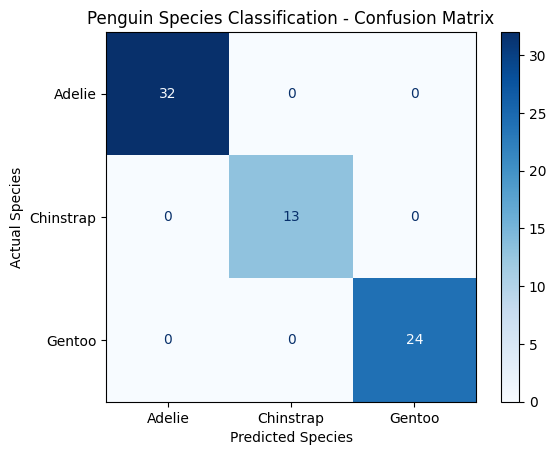

In [69]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=lr.classes_
)

disp.plot(cmap='Blues', values_format='d')

plt.title("Penguin Species Classification - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [70]:
print("Classification Report")
print("---------------------")

print(classification_report(y_test, y_pred))

Classification Report
---------------------
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        32
   Chinstrap       1.00      1.00      1.00        13
      Gentoo       1.00      1.00      1.00        24

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



## 9. Limitations and Future Improvements

Potential limitations and future improvements include:

- Overlapping physical measurements between some penguin species.
- Limited dataset size.
- Exploring additional classification algorithms for comparison.
- Applying cross-validation to obtain more reliable performance estimates.
- Investigating feature importance and decision boundaries.